# Crank-Nicolson vs PINN vs PIKAN

In this comparison I will use my Crank-Nicolson solver, the wider PINN with modified loss function and the PIKAN with 3000 epoch training length as I found these to be the "best" versions of each neural network type. 

All methods use the same parameters and are evaluated against the analytical Black-Scholes solution.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
# Parameters and grid used.

K = 100
T = 1.0
r = 0.05
sigma = 0.2
S_max = 3 * K

evaluation_grid = "100 x 50"

In [13]:
# Comparison of different PINN architectures and training strategies.

pinn_results = pd.DataFrame([
    {
        "Model": "Baseline PINN",
        "Architecture": "[2, 32, 32, 32, 1]",
        "Scheduler": "No",
        "Loss": "Standard",
        "Epochs": 5000,
        "Runtime (s)": 51.9,
        "Runtime per Epoch (s)": 0.01038,
        "MSE": 0.250624,
        "RMSE": 0.500623,
        "MAE": 0.363268,
        "Max Abs Error": 4.505993,
        "Relative L2 Error": 0.005180,
    },
    {
        "Model": "Wider PINN",
        "Architecture": "[2, 64, 64, 64, 1]",
        "Scheduler": "No",
        "Loss": "Standard",
        "Epochs": 5000,
        "Runtime (s)": 71.1,
        "Runtime per Epoch (s)": 0.01422,
        "MSE": 	0.482299,
        "RMSE": 0.694477,
        "MAE": 0.562019,
        "Max Abs Error": 5.379873,
        "Relative L2 Error": 0.007186,
    },
    {
        "Model": "Wider PINN + LR Scheduler",
        "Architecture": "[2, 64, 64, 64, 1]",
        "Scheduler": "StepLR",
        "Loss": "Standard",
        "Epochs": 5000,
        "Runtime (s)": 65,
        "Runtime per Epoch (s)": 0.013,
        "MSE": 1.963900,
        "RMSE": 1.401392,
        "MAE": 0.992939,
        "Max Abs Error": 7.813058,
        "Relative L2 Error": 0.014500,
    },
    {
        "Model": "Wider PINN + Lr Scheduler + Modified Loss",
        "Architecture": "[2, 64, 64, 64, 1]",
        "Scheduler": "StepLR",
        "Loss": "Weighted IC",
        "Epochs": 5000,
        "Runtime (s)": 95.9,
        "Runtime per Epoch (s)": 0.01918,
        "MSE": 0.267159,
        "RMSE": 0.516874,
        "MAE": 0.447378,
        "Max Abs Error": 3.750791,
        "Relative L2 Error": 0.005348,
    },

    {
        "Model": "Baseline PINN + Modified Loss",
        "Architecture": "[2, 32, 32, 32, 1]",
        "Scheduler": "No",
        "Loss": "Weighted IC",
        "Epochs": 5000,
        "Runtime (s)": 55.7,
        "Runtime per Epoch (s)": 0.01114,
        "MSE": 0.220308,
        "RMSE": 0.469370,
        "MAE": 0.387819,
        "Max Abs Error": 3.454764,
        "Relative L2 Error": 0.004857,
    }
])

pinn_results

,Model,Architecture,Scheduler,Loss,Epochs,Runtime (s),Runtime per Epoch (s),MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Baseline PINN,"[2, 32, 32, 32, 1]",No,Standard,5000,51.9,0.01038,0.250624,0.500623,0.363268,4.505993,0.005180
1,Wider PINN,"[2, 64, 64, 64, 1]",No,Standard,5000,71.1,0.01422,0.482299,0.694477,0.562019,5.379873,0.007186
2,Wider PINN + LR Scheduler,"[2, 64, 64, 64, 1]",StepLR,Standard,5000,65.0,0.01300,1.963900,1.401392,0.992939,7.813058,0.014500
3,Wider PINN + Lr Scheduler + Modified Loss,"[2, 64, 64, 64, 1]",StepLR,Weighted IC,5000,95.9,0.01918,0.267159,0.516874,0.447378,3.750791,0.005348
4,Baseline PINN + Modified Loss,"[2, 32, 32, 32, 1]",No,Weighted IC,5000,55.7,0.01114,0.220308,0.469370,0.387819,3.454764,0.004857


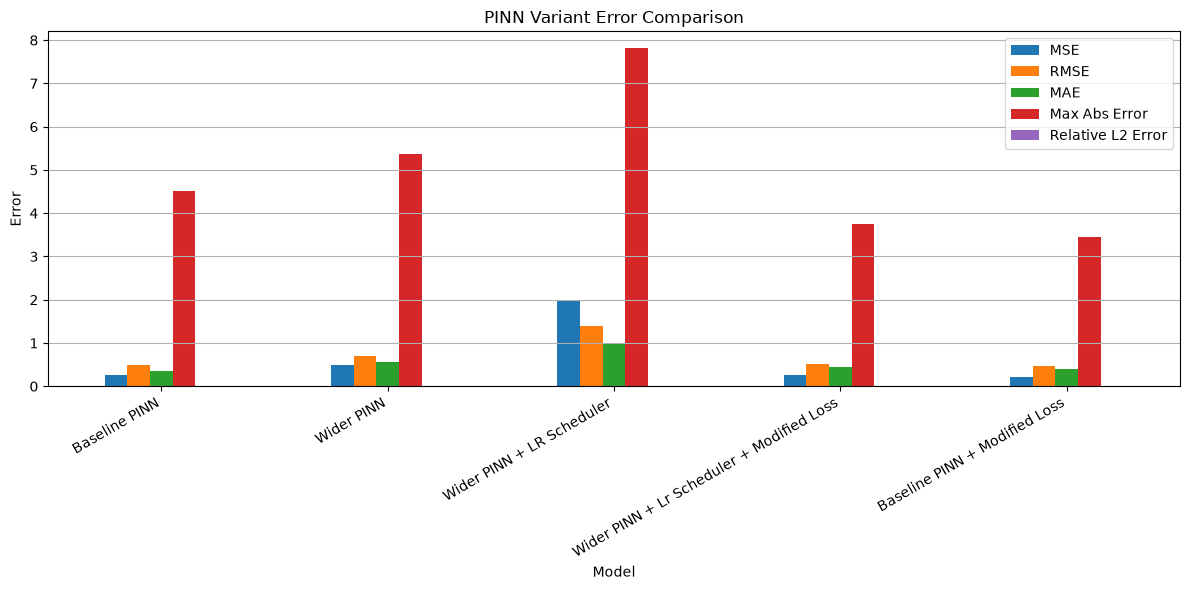

In [14]:
metric_cols = ["MSE", "RMSE", "MAE", "Max Abs Error", "Relative L2 Error"]

pinn_results.plot(
    x="Model",
    y=metric_cols,
    kind="bar",
    figsize=(12, 6),
)

plt.title("PINN Variant Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

Among the PINN architectures the Baseline PINN with weighted IC performed best. Adding a learning rate scheduler nor making the PINN wider improved performance.

In [21]:
# Comparison of PIKAN and PINN with the analytical solution.

best_pinn = pinn_results.loc[pinn_results["RMSE"].idxmin()].to_dict()

pikan_result = {
    "Model": "PIKAN",
    "Architecture": "[2, 16, 16, 1], grid=5, degree=3",
    "Scheduler": "No",
    "Loss": "Standard physics-informed loss",
    "Epochs": 3000,
    "Runtime (s)": 282.4,
    "Runtime per Epoch (s)": 0.0941333,
    "MSE": 0.003373,
    "RMSE": 0.058075,
    "MAE": 0.033826,
    "Max Abs Error": 1.629618,
    "Relative L2 Error": 0.000601,
}

pikan_result_short = {
    "Model": "PIKAN (1000 epochs)",
    "Architecture": "[2, 16, 16, 1], grid=5, degree=3",
    "Scheduler": "No",
    "Loss": "Standard physics-informed loss",
    "Epochs": 1000,
    "Runtime (s)": 84.9,
    "Runtime per Epoch (s)": 0.0849,
    "MSE": 0.082062,
    "RMSE": 0.286464,
    "MAE": 	0.204735,
    "Max Abs Error": 3.646942,
    "Relative L2 Error": 0.002964,
}

pinn_vs_pikan = pd.DataFrame([
    {
        "Model": best_pinn["Model"],
        "Architecture": best_pinn["Architecture"],
        "Epochs": best_pinn["Epochs"],
        "Runtime (s)": best_pinn["Runtime (s)"],
        "Runtime per Epoch (s)": best_pinn["Runtime per Epoch (s)"],
        "MSE": best_pinn["MSE"],
        "RMSE": best_pinn["RMSE"],
        "MAE": best_pinn["MAE"],
        "Max Abs Error": best_pinn["Max Abs Error"],
        "Relative L2 Error": best_pinn["Relative L2 Error"],
        "Scheduler": "No",
        "Loss": "Weighted IC"
    },
    pikan_result,
    pikan_result_short
])

pinn_vs_pikan

,Model,Architecture,Epochs,Runtime (s),Runtime per Epoch (s),MSE,RMSE,MAE,Max Abs Error,Relative L2 Error,Scheduler,Loss
0,Baseline PINN + Modified Loss,"[2, 32, 32, 32, 1]",5000,55.7,0.011140,0.220308,0.469370,0.387819,3.454764,0.004857,No,Weighted IC
1,PIKAN,"[2, 16, 16, 1], grid=5, degree=3",3000,282.4,0.094133,0.003373,0.058075,0.033826,1.629618,0.000601,No,Standard physics-informed loss
2,PIKAN (1000 epochs),"[2, 16, 16, 1], grid=5, degree=3",1000,84.9,0.084900,0.082062,0.286464,0.204735,3.646942,0.002964,No,Standard physics-informed loss


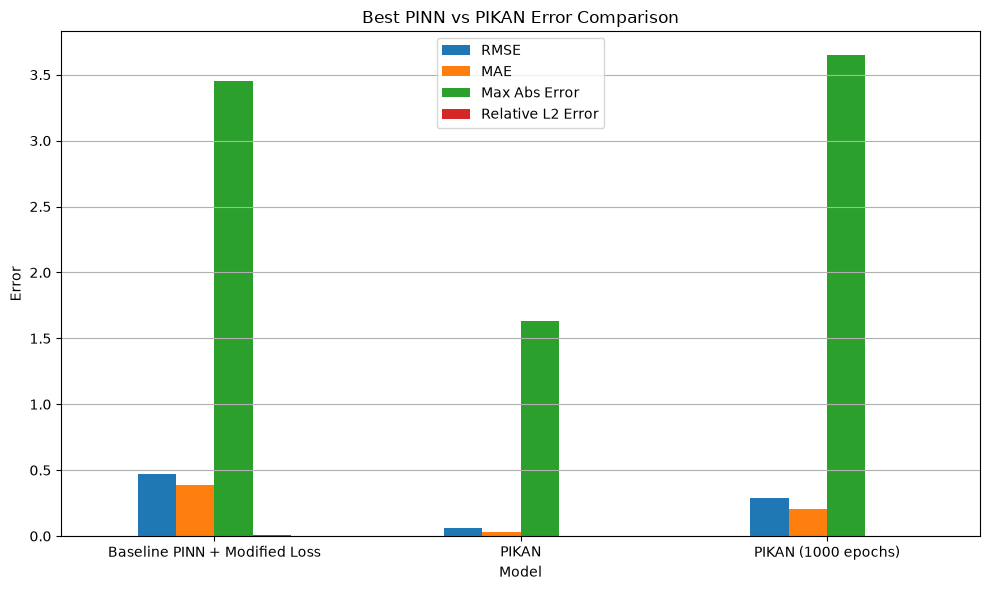

In [24]:
pinn_vs_pikan.plot(
    x="Model",
    y=["RMSE", "MAE", "Max Abs Error", "Relative L2 Error"],
    kind="bar",
    figsize=(10, 6),
)

plt.title("Best PINN vs PIKAN Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

The PIKAN (3000 epochs) considerably outperformed the best PINN in all errors, in exchange it had a significantly longer runtime.

However, the PIKAN (1000 epochs) offered lower erros across all categories than the best PINN (except max absolute error, which occurs at the initial condition) with a slightly longer runtime.

In [23]:
# Final comparison table for the best PINN and PIKAN vs Crank-Nicolson. I will use the 3000 epoch PIKAN.

final_comparison = pd.DataFrame([
    {
    "Method": "Crank-Nicolson",
    "Architecture / Grid": "M=100, N=100",
    "Trainable Parameters": 0,
    "Epochs": "N/A",
    "Training Points": "N/A",
    "Evaluation Grid": evaluation_grid,
    "Runtime (s)": 0.5141,
    "Runtime per Epoch (s)": "N/A",
    "MSE": 0.000096,
    "RMSE": 0.009815,
    "MAE": 0.003887,
    "Max Abs Error": 0.129387,
    "Relative L2 Error": 0.000102,
    },
    {
        "Method": "Baseline PINN + Modified Loss",
        "Architecture / Grid": "[2, 32, 32, 32, 1], Weighted IC",
        "Trainable Parameters": 2241,
        "Epochs": 5000,
        "Training Points": "N_f=500, N_ic=200, N_bc=200",
        "Evaluation Grid": evaluation_grid,
        "Runtime (s)": 55.1,
        "Runtime per Epoch (s)": 0.01102,
        "MSE": 0.220308,
        "RMSE": 0.469370,
        "MAE": 0.387819,
        "Max Abs Error": 3.454764,
        "Relative L2 Error": 0.004857,
    },
    {
        "Method": "PIKAN",
        "Architecture / Grid": "[2, 16, 16, 1], grid=5, degree=3",
        "Trainable Parameters": 4256,
        "Epochs": 3000,
        "Training Points": "N_f=300, N_ic=150, N_bc=150",
        "Evaluation Grid": evaluation_grid,
        "Runtime (s)": 282.4,
        "Runtime per Epoch (s)": 0.941333,
        "MSE": 0.003373,
        "RMSE": 0.058075,
        "MAE": 0.033826,
        "Max Abs Error": 1.629618,
        "Relative L2 Error": 0.000601,
    },
])

final_comparison

,Method,Architecture / Grid,Trainable Parameters,Epochs,Training Points,Evaluation Grid,Runtime (s),Runtime per Epoch (s),MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Crank-Nicolson,"M=100, N=100",0,N/A,N/A,100 x 50,0.5141,N/A,0.000096,0.009815,0.003887,0.129387,0.000102
1,Baseline PINN + Modified Loss,"[2, 32, 32, 32, 1], Weighted IC",2241,5000,"N_f=500, N_ic=200, N_bc=200",100 x 50,55.1000,0.01102,0.220308,0.469370,0.387819,3.454764,0.004857
2,PIKAN,"[2, 16, 16, 1], grid=5, degree=3",4256,3000,"N_f=300, N_ic=150, N_bc=150",100 x 50,282.4000,0.941333,0.003373,0.058075,0.033826,1.629618,0.000601


Crank-Nicolson achieved the lowest error across all metrics. This is expected because it is a classical finite-difference method designed specifically for parabolic PDEs such as Black-Scholes. The PIKAN substantially outperformed the PINN, achieving lower MSE, RMSE, MAE, maximum absolute error, and relative L2 error. However, the Crank-Nicolson method remained the most accurate benchmark on this standard European call option problem.